### TEL328 - Procesamiento Digital de Imágenes
# Clase 10: Detección de objetos
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Introducción

- En el contexto de imágenes, no solo es posible tener clases como salida.
- También es posible resolver problemas de localización de los objetos, o incluso obtener máscaras de segmentación y otras representaciones (e.g. modelos articulados).


<div align="center">
    <img src="img/tasks.png" alt="" width="60%" align="center" />
</div>

# Modelos para detección de objetos

- Aquellos modelos que trabajan en clasificar y a su vez localizar los objetos, ya sea mediante cuadros delimitadores (bounding boxes) o segmentación, son conocidos como la familia de Region-based CNN o R-CNN.
- El modelo precursor es R-CNN [Girshick et al., 2013], luego Fast-RCNN [Girshick, 2015], luego YOLO [Redmon et al., 2015], y finalmente Faster-RCNN [Ren et al., 2015], todos capaces de clasificar y localizar mediante bounding boxes en una imagen a los objetos presentes en la escena, para los cuales fueron entrenados.
- Mask-RCNN [He et al., 2017] además agrega la posibilidad de generar una máscara de  segmentación.

# R-CNN

- R-CNN crea *bounding boxes* (cuadros/cajas delimitadores), que son regiones propuestas, usando un proceso llamado Búsqueda Selectiva.

- En un nivel alto, la búsqueda selectiva examina la imagen a través de ventanas de diferentes tamaños y, para cada tamaño, intenta agrupar los píxeles adyacentes por textura, color o intensidad para identificar los objetos.

- La arquitectura R-CNN (Regiones con redes neuronales convolucionales) es una combinación de múltiples algoritmos juntos. Primero utiliza un algoritmo de búsqueda selectiva para seleccionar 2000 propuestas de regiones que pueden contener objetos. Cada una de estas propuestas de regiones o Regiones de Interés (RoIs) se procesa a través de una red convolucional para obtener mapas de características. Luego, los mapas de características se pasan a un modelo SVM para clasificar la clase de objeto y a un modelo de regresión para obtener cajas delimitadoras estrechas. Este método, aunque novedoso en su tiempo, es extremadamente lento.

# Selective Search

<div align="center">
    <img src="img/selectivesearch.png" alt="" width="50%" align="center" />
</div>

<div align="center">
    <img src="img/RCNN.png" alt="" width="80%" align="center" />
</div>

# Faster R-CNN en Python con torch

In [ ]:
# Instalar torch de ser necesario
# !pip install torch

In [2]:
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    FasterRCNN_ResNet50_FPN_Weights
)
from PIL import Image
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches

In [6]:
def detectar_objetos_rcnn(path):
    # -----------------------------
    # Cargar modelo
    # -----------------------------
    weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
    model = fasterrcnn_resnet50_fpn(weights=weights)
    model.eval()

    # -----------------------------
    # Cargar imagen
    # -----------------------------
    image = Image.open(path).convert("RGB")
    transform = weights.transforms()

    x = transform(image)

    # -----------------------------
    # Detectar objetos
    # -----------------------------
    with torch.no_grad():
        result = model([x])[0]

    # -----------------------------
    # Mostrar imagen
    # -----------------------------
    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(image)
    ax.axis("off")

    # -----------------------------
    # Dibujar detecciones
    # -----------------------------
    for box, label, score in zip(
        result["boxes"],
        result["labels"],
        result["scores"]
    ):
        if score > 0.7:

            x1, y1, x2, y2 = box.tolist()

            nombre = weights.meta["categories"][label]

            # Bounding box
            rect = patches.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                linewidth=2,
                edgecolor="red",
                facecolor="none"
            )

            ax.add_patch(rect)

            # Etiqueta
            ax.text(
                x1,
                y1,
                f"{nombre} {score:.2f}",
                fontsize=10,
                color="white",
                backgroundcolor="red"
            )

            # Imprimir detección
            print(
                f"{nombre}: {score:.2f}"
            )

    plt.show()

car: 0.99
car: 0.99
car: 0.98
bicycle: 0.98
person: 0.96
car: 0.94
car: 0.92
truck: 0.90
car: 0.86
car: 0.85
vase: 0.79
truck: 0.76


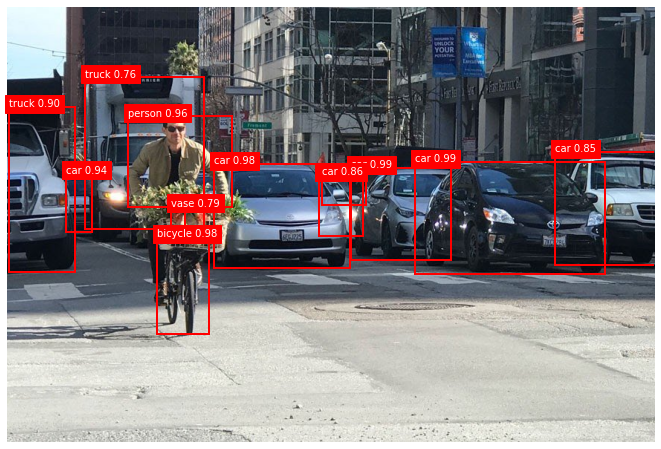

In [10]:
detectar_objetos_rcnn("test/bike.jpg")

# YOLO

- *You only look once* (YOLO) [Redmon et al., 2015] es un modelo de detección de objetos orientado a tiempo real.

- La filosofía es bastante diferente de los R-CNN, pues no considera regiones candidatas.

- En lugar de localizar objetos perfectamente, prioriza la velocidad y el reconocimiento.

- YOLO aplica una sola red neuronal a la imagen completa. Esta red divide la imagen en regiones y predice cuadros delimitadores y probabilidades para cada región. Estos cuadros delimitadores están ponderados por las probabilidades predichas.

## Algoritmo YOLO

- YOLO divide la imagen de entrada en una grilla de $S \times S$.
- Si el centro de un objeto cae dentro de una celda, esa celda es responsable de detectar ese objeto. 
- Cada celda predice $B$ *bounding boxes* (cuadros delimitadores) y puntajes de confianza para esos cuadros. 
- Estos puntajes de confianza reflejan qué tan seguro está el modelo de que la caja contiene un objeto y qué tan precisa cree que es la caja que predice. 
-  Si no existe ningún objeto en esa celda, las puntuaciones de confianza deben ser cero. 

### Dividir la imagen en una grilla de $S \times S$ celdas

- Cada una de estas celdas es responsable de predecir $B$ *bounding boxes* (cuadros delimitadores)
- Un cuadro delimitador describe el rectángulo que encierra un objeto. 
- YOLO también genera una puntuación de confianza que nos dice qué tan seguro es que el cuadro delimitador predicho realmente encierra algún objeto. 
- Esta puntuación no dice nada sobre qué tipo de objeto hay en la caja, solo si la forma de la caja es correcta.

<div align="center">
    <img src="img/grid.jpg" alt="" width="30%" align="center" />
</div>

### Bounding Boxes

Para cada cuadro delimitador, la celda también predice una clase. Esto funciona como un clasificador: da una distribución de probabilidad sobre todas las clases posibles.

<div align="center">
    <img src="img/boxes.jpg" alt="" width="30%" align="center" />
</div>

### Probabilidad de clase

La puntuación de confianza para el cuadro delimitador y la predicción de clase se combinan en una puntuación final que nos indica la probabilidad de que este cuadro delimitador contenga un tipo específico de objeto.

<div align="center">
    <img src="img/class.jpg" alt="" width="30%" align="center" />
</div>

### Combinación entre los cuadros delimitadores y la probabilidad de clase

La mayoría de los cuadros delimitadores tendrán una probabilidad de clase muy baja. Por lo tanto, se mantienen solo las que superen un cierto umbral.

<div align="center">
    <img src="img/combination.jpg" alt="" width="30%" align="center" />
</div>

### Mantener solo las que superan un cierto umbral

<div align="center">
    <img src="img/detection.jpg" alt="" width="30%" align="center" />
</div>

### Predicción

Cada cuadro delimitador consta de 5 predicciones: $x$, $y$, $w$, $h$ y confianza. Las coordenadas $(x, y)$ representan el centro de la caja en relación a los límites de la celda. El ancho y la altura se predicen en relación con la imagen completa.

<div align="center">
    <img src="img/prediction.png" alt="" width="30%" align="center" />
</div>

## El Modelo YOLO

<div align="center">
    <img src="img/YOLO.jpg" alt="" width="50%" align="center" />
</div>

Modela la detección como un problema de regresión. Divide la imagen en una cuadrícula S × S y para cada celda predice $B$ cuadros delimitadores, la confianza de esos cuadros y $C$ probabilidades de clase. Estas predicciones están codificadas como un tensor $S \times S \times (B ∗ 5 + C)$.

## La Arquitectura de YOLO

<div align="center">
    <img src="img/YOLOred.jpg" alt="" width="70%" align="center" />
</div>

24 capas convolucionales, seguidas de 2 FC.

# YOLOv3 en Python

## Librerías necesarias
* `torch` (Instalar con `pip install torch`).
* `matplotlib`, para graficar las imágenes.
* `PIL`, para ajustar el tamaño de la imagen de entrada con la función `resize()`.
* `utils`, módulo que contiene algunas funciones auxiliares.
* `Darknet`, versión modificada de [Darknet](https://pjreddie.com/darknet/), un framework open source de Deep Learning escrito por los creadores de YOLO.
* No se entrenará la red. En su lugar, se usarán pesos pre-entrenados que fueron entrenados con el dataset [COCO](https://cocodataset.org/#home) (Common Objects in Context).

In [15]:
# Importar librerias y funciones auxiliares
from YOLO.utils import *
from YOLO.darknet import Darknet

## Configuración de la red neuronal

* El archivo `yolov3.cfg` contiene la arquitectura de la red usada por YOLOv3 y está localizada en la carpeta `/cfg/`.
* Similarmente, el archivo `yolov3.weights` contiene los pesos pre-entrenados y está ubicado en la carpeta `/weights/`.
* Finalmente, la carpeta `/data/`, contiene el archivo `coco.names` con una lista con las 80 clases diferentes de objetos que los pesos fueron entrenados para detectar.

In [16]:
# Definir la ubicación y nombre del archivo con cfg
cfg_file = 'YOLO/cfg/yolov3.cfg'

# Definir la ubicación y nombre del archivo con los pesos pre-entrenados
weight_file = 'YOLO/weights/yolov3.weights'

# Definir la ubicación y nombre del archivo con las clases
namesfile = 'YOLO/data/coco.names'

# Cargar la arquitectura de la red
yolo_model = Darknet(cfg_file)

# Cargar los pesos pre-entrenados
yolo_model.load_weights(weight_file)

# Cargar las clases de objetos del dataset COCO desde utils.py
class_names = load_class_names(namesfile)

## Resumen de la red neuronal
Podemos imprimir la red usando la función `.print_network()`.

In [17]:
# Imprimir la arquitectura de la red neuronal usada por YOLOv3
yolo_model.print_network()

layer     filters    size              input                output
    0 conv     32  3 x 3 / 1   416 x 416 x   3   ->   416 x 416 x  32
    1 conv     64  3 x 3 / 2   416 x 416 x  32   ->   208 x 208 x  64
    2 conv     32  1 x 1 / 1   208 x 208 x  64   ->   208 x 208 x  32
    3 conv     64  3 x 3 / 1   208 x 208 x  32   ->   208 x 208 x  64
    4 shortcut 1
    5 conv    128  3 x 3 / 2   208 x 208 x  64   ->   104 x 104 x 128
    6 conv     64  1 x 1 / 1   104 x 104 x 128   ->   104 x 104 x  64
    7 conv    128  3 x 3 / 1   104 x 104 x  64   ->   104 x 104 x 128
    8 shortcut 5
    9 conv     64  1 x 1 / 1   104 x 104 x 128   ->   104 x 104 x  64
   10 conv    128  3 x 3 / 1   104 x 104 x  64   ->   104 x 104 x 128
   11 shortcut 8
   12 conv    256  3 x 3 / 2   104 x 104 x 128   ->    52 x  52 x 256
   13 conv    128  1 x 1 / 1    52 x  52 x 256   ->    52 x  52 x 128
   14 conv    256  3 x 3 / 1    52 x  52 x 128   ->    52 x  52 x 256
   15 shortcut 12
   16 conv    128  1 x 1

## Hiperparámetros del modelo

- Non-Maximal Suppression (`nms`) 
- Intersection Over Union (`iou`)

#### ¿Para qué se usa Non-Maximal Suppression (nms) en YOLO? 

YOLO usa el principio Non-Maximal Suppression (NMS) para mantener solo el mejor cuadro delimitador. El primer paso en NMS es eliminar todos los cuadros delimitadores predichos que tienen una probabilidad de detección menor que un umbral NMS dado.

<div align="center">
    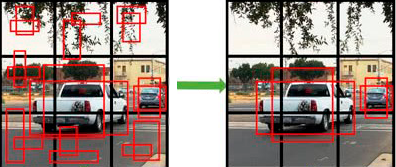
</div>

Después de eliminar todos los cuadros delimitadores predichos que tienen una probabilidad de detección baja, el segundo paso en NMS es seleccionar los cuadros delimitadores con la probabilidad de detección más alta y eliminar todos los cuadros delimitadores cuyo valor de Intersección sobre unión (IOU) sea mayor que un umbral determinado.

#### ¿Qué es Intersection Over Union (IoU)? 

Es un valor utilizado en la detección de objetos para medir la superposición de un cuadro delimitador predicho versus el real. Cuanto más cerca estén los valores predichos del cuadro delimitador de los valores reales del cuadro delimitador, mayor será la intersección y mayor será el valor de IoU.

<div align="center">
    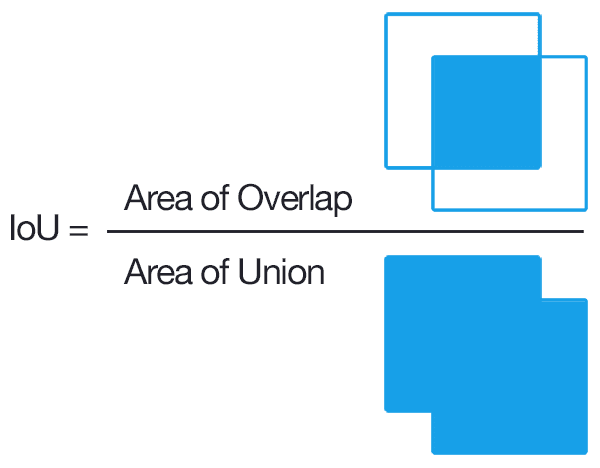
</div>


### IoU Threshold

<div align="center">
    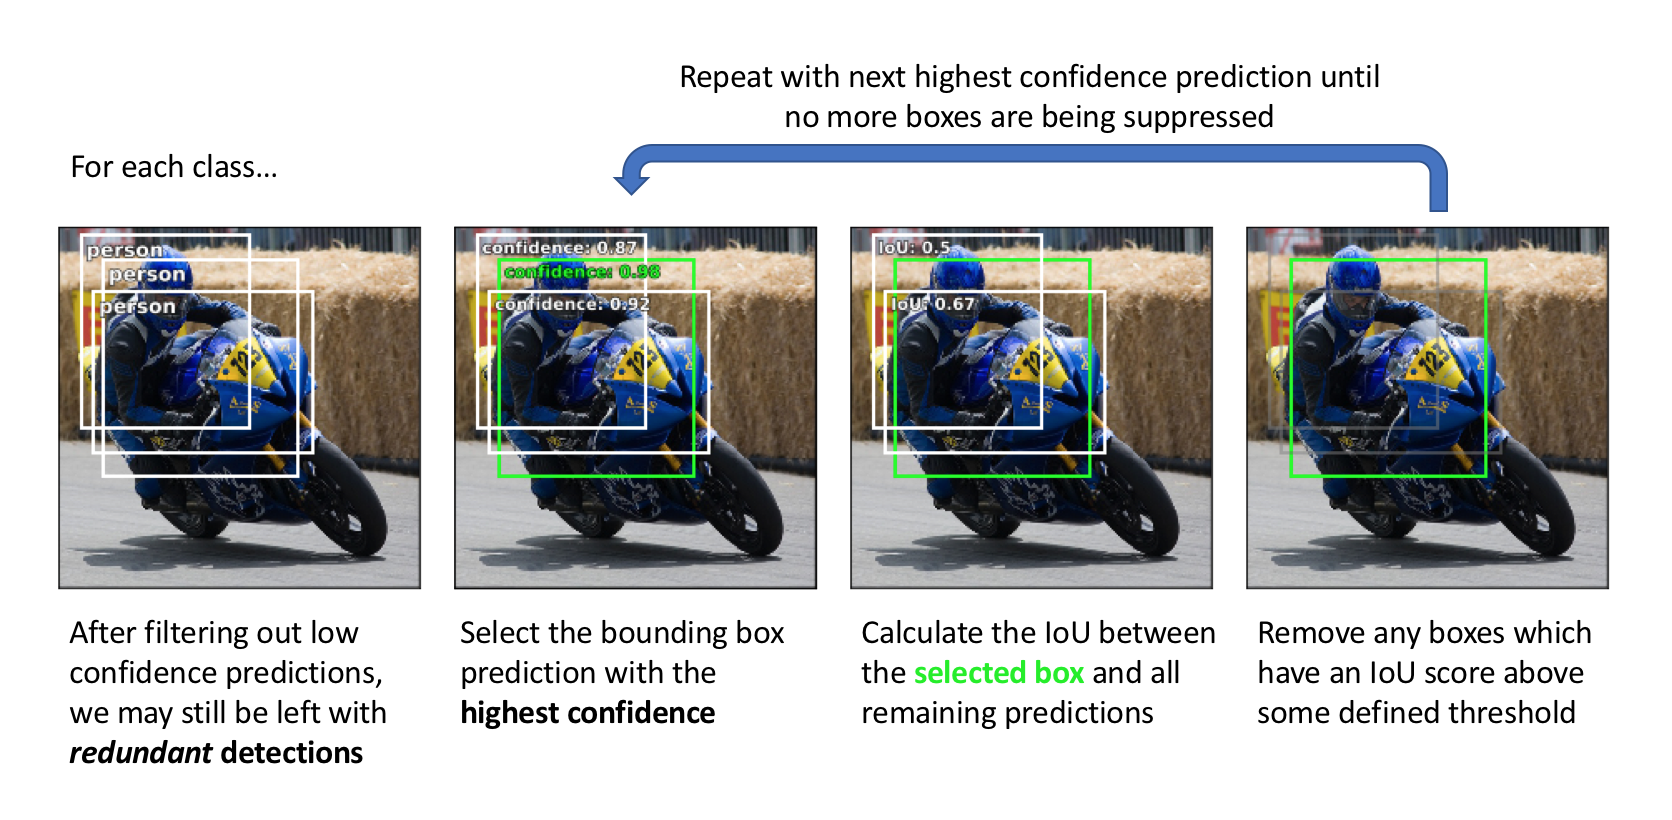
</div>

# YOLOv3 en Python 

In [18]:
def detectar_objetos_yolo(model, path, iou_thresh=0.4, nms_thresh=0.6, verbose=True):
    img = Image.open(path)
    original_image = np.array(img)
    resized_image = img.resize((model.width, model.height))
    resized_image = np.array(resized_image)
    boxes = detect_objects(model, resized_image, iou_thresh, nms_thresh, verbose=verbose)
    if verbose: print_objects(boxes, class_names)
    plot_boxes(original_image, boxes, class_names, plot_labels = True)    

Number of Objects Detected: 9 (in 1.313 seconds)
1. car: 0.999995
2. car: 0.999995
3. car: 0.999971
4. car: 0.908282
5. car: 0.633678
6. person: 0.999534
7. car: 0.999976
8. truck: 0.497272
9. bicycle: 1.000000


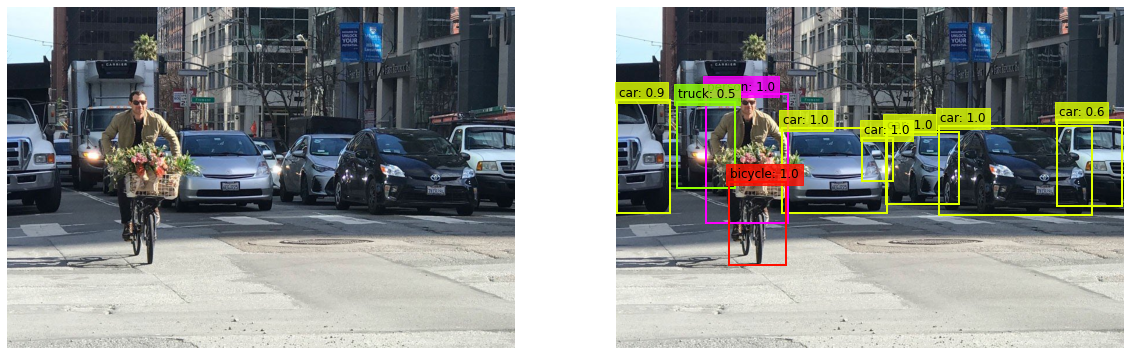

In [19]:
detectar_objetos_yolo(yolo_model,'test/bike.jpg')

In [7]:
import os
import re

In [8]:
def detectar_todo(model, directory, iou_thresh=0.4, nms_thresh=0.6, verbose=False):
    for filename in os.listdir(directory):
        f = os.path.join(directory, filename)
        if re.search("\.(jpg)$", filename):        
            img = Image.open(f)
            original_image = np.array(img)            
            resized_image = img.resize((model.width, model.height))
            resized_image = np.array(resized_image)            
            boxes = detect_objects(model, resized_image, iou_thresh, nms_thresh, verbose=verbose)
            if verbose: print_objects(boxes, class_names)
            plot_boxes(original_image, boxes, class_names, plot_labels = True) 

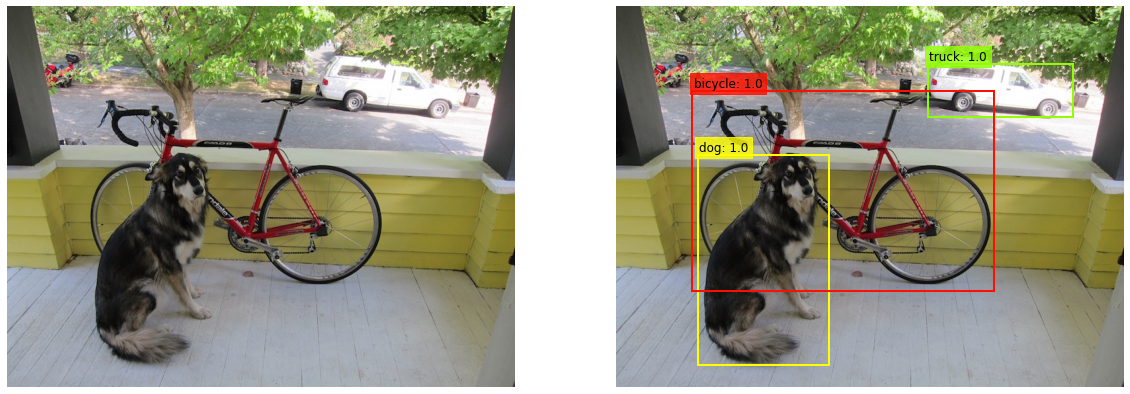

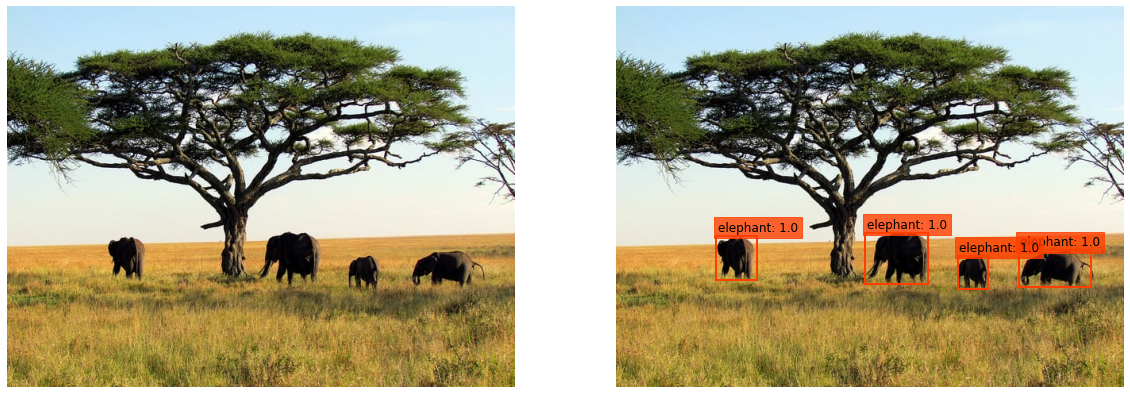

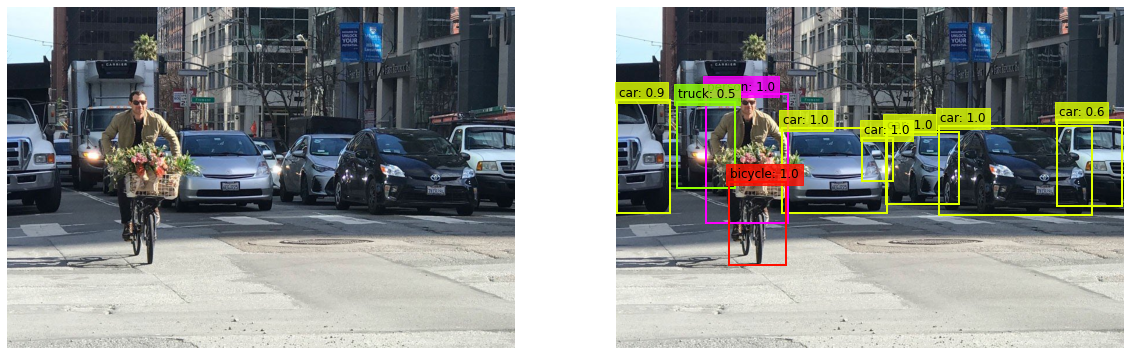

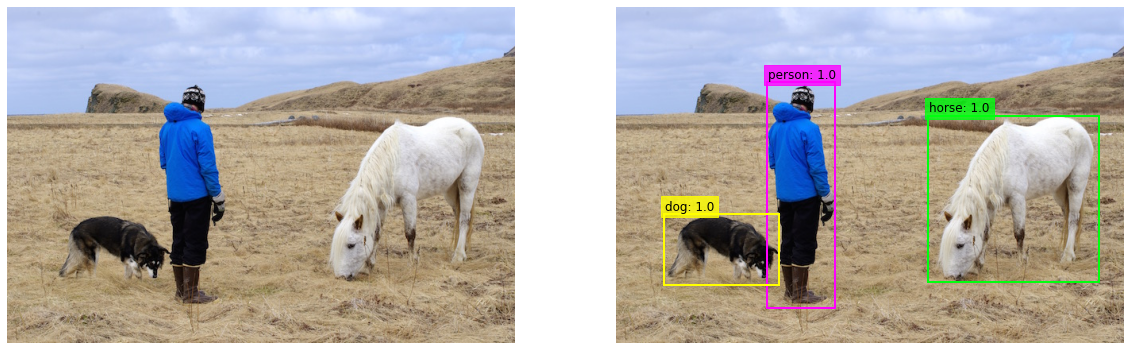

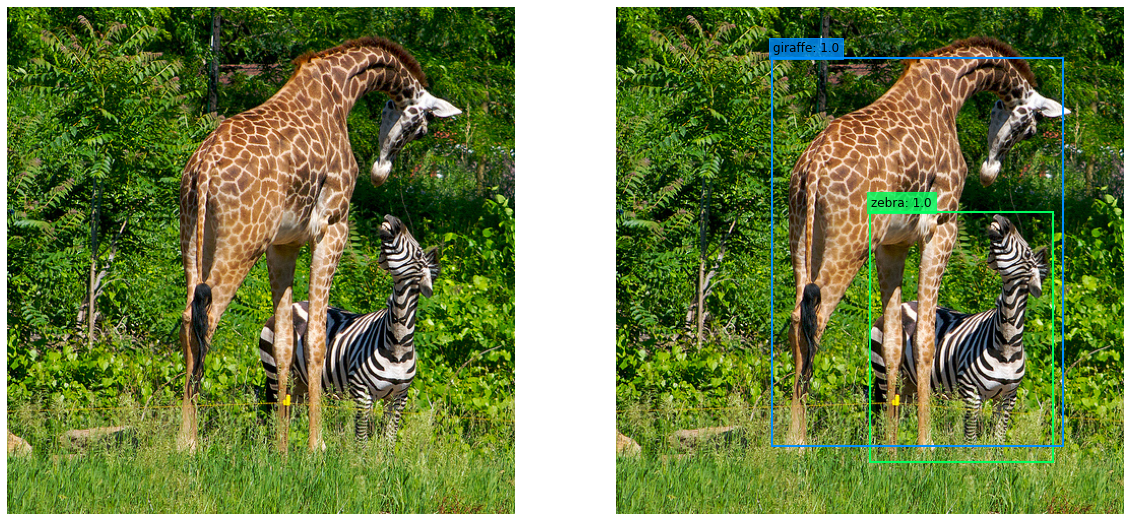

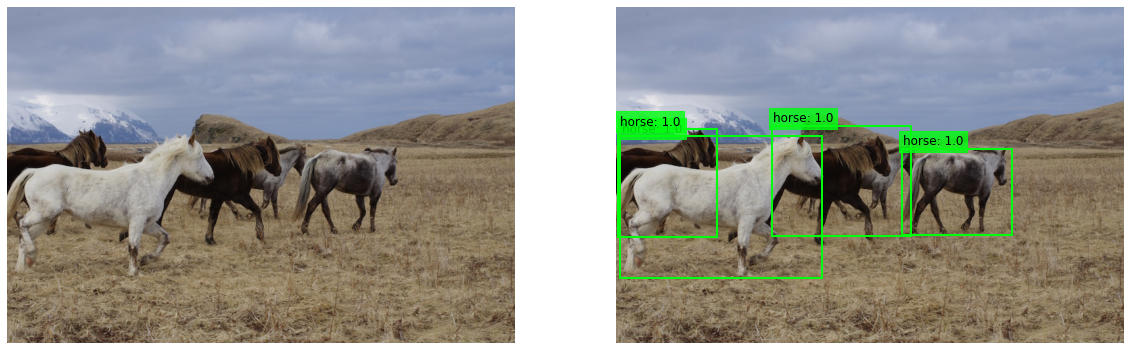

In [9]:
detectar_todo(yolo_model, "test")